In [ ]:
from os import makedirs
!pip install pandas matplotlib seaborn

In [27]:
import json
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import re

In [39]:

def load_data(jsonl_path: str) -> pd.DataFrame:
    """Loads the benchmark results from a .jsonl file into a pandas DataFrame."""
    records = []
    with open(jsonl_path, 'r') as f:
        for line in f:
            # Each line is a JSON object representing an EnrichedResult
            # We flatten the nested solver_result into the main record
            record = json.loads(line)
            solver_data = record.pop('solver_result')
            record.update(solver_data)
            records.append(record)

    df = pd.DataFrame(records)
    # --- Data Cleaning and Preparation ---
    # Convert numeric columns from strings where necessary
    df['iters'] = pd.to_numeric(df['iters'], errors='coerce') # 'N/A' becomes NaN

    # Create a total CPU time column
    df['total_cpu_time_s'] = df['cpu_user_time_s'] + df['cpu_system_time_s']

    return df


In [40]:
def analyze_failed_tests(log_path: str) -> pd.DataFrame:
    """
    Analyzes a log file to find which solver and matrix combinations failed,
    including tests that were interrupted or did not complete.
    """
    print(f"📄 Analyzing log file: {log_path}...")
    failures = []

    # Regex patterns
    run_pattern = re.compile(r"Running test: ([\w\(\)]+) on (\w+)")
    fail_pattern = re.compile(r"ERROR testrunner: Test failed")
    success_pattern = re.compile(r"--- Finished:")

    current_test = None

    try:
        with open(log_path, 'r') as f:
            lines = f.readlines()
    except FileNotFoundError:
        print(f"Error: Log file not found at {log_path}")
        return pd.DataFrame()

    for line in lines:
        run_match = run_pattern.search(line)

        if run_match:
            # A new test is starting. Check if the previous one finished.
            if current_test:
                # If a test was running but didn't log success/fail, it's a failure.
                failures.append({
                    'solver_name': current_test['solver'],
                    'matrix_name': current_test['matrix'],
                    'status': 'Failed (Interrupted)'
                })

            # Set the new current test
            current_test = {'solver': run_match.group(1), 'matrix': run_match.group(2)}
            continue

        if current_test:
            # Check for the outcome of the currently tracked test
            if fail_pattern.search(line):
                failures.append({
                    'solver_name': current_test['solver'],
                    'matrix_name': current_test['matrix'],
                    'status': 'Failed (Explicit Error)'
                })
                current_test = None # Reset, as this test's outcome is known
            elif success_pattern.search(line):
                # Test succeeded, reset.
                current_test = None

    # After the loop, if a test was running and never finished, it's also a failure.
    if current_test:
        failures.append({
            'solver_name': current_test['solver'],
            'matrix_name': current_test['matrix'],
            'status': 'Failed (Did not finish)'
        })

    if not failures:
        print("✅ No failed tests found in the log file.")
        return pd.DataFrame(columns=['solver_name', 'matrix_name', 'status'])

    return pd.DataFrame(failures)

In [41]:
def analyze_failed_tests(log_path: str) -> pd.DataFrame:
    """
    Analyzes a log file to find which solver and matrix combinations failed,
    including tests that were interrupted or did not complete.
    """
    print(f"📄 Analyzing log file: {log_path}...")
    failures = []

    # Regex patterns
    run_pattern = re.compile(r"Running test: ([\w\(\)]+) on (\w+)")
    # --- FIX: Make the fail pattern more general to catch any testrunner error ---
    fail_pattern = re.compile(r"ERROR testrunner:")
    success_pattern = re.compile(r"--- Finished:")

    current_test = None

    try:
        with open(log_path, 'r') as f:
            lines = f.readlines()
    except FileNotFoundError:
        print(f"Error: Log file not found at {log_path}")
        return pd.DataFrame()

    for line in lines:
        run_match = run_pattern.search(line)

        if run_match:
            # A new test is starting. Check if the previous one finished.
            if current_test:
                # If a test was running but didn't log success/fail, it's a failure.
                failures.append({
                    'solver_name': current_test['solver'],
                    'matrix_name': current_test['matrix'],
                    'status': 'Failed (Interrupted)'
                })

            # Set the new current test
            current_test = {'solver': run_match.group(1), 'matrix': run_match.group(2)}
            continue

        if current_test:
            # Check for the outcome of the currently tracked test
            if fail_pattern.search(line):
                failures.append({
                    'solver_name': current_test['solver'],
                    'matrix_name': current_test['matrix'],
                    'status': 'Failed (Explicit Error)'
                })
                current_test = None # Reset, as this test's outcome is known
            elif success_pattern.search(line):
                # Test succeeded, reset.
                current_test = None

    # After the loop, if a test was running and never finished, it's also a failure.
    if current_test:
        failures.append({
            'solver_name': current_test['solver'],
            'matrix_name': current_test['matrix'],
            'status': 'Failed (Did not finish)'
        })

    if not failures:
        print("✅ No failed tests found in the log file.")
        return pd.DataFrame(columns=['solver_name', 'matrix_name', 'status'])

    return pd.DataFrame(failures)


In [62]:
failed_tests_df = analyze_failed_tests("log.txt")
failed_tests_df

📄 Analyzing log file: log.txt...


,solver_name,matrix_name,status
0,LU,DWT_592,Failed (Interrupted)
1,LU,BCSSTM01,Failed (Interrupted)
2,LU,DWT_607,Failed (Interrupted)
3,BiCGSTAB,BCSSTM21,Failed (Interrupted)
4,LU,BCSSTK37,Failed (Interrupted)
...,...,...,...
105,CG,BCSSTK33,Failed (Interrupted)
106,GMRES,BCSSTK37,Failed (Interrupted)
107,BiCGSTAB,BCSSTK30,Failed (Interrupted)
108,GMRES,CEGB2919,Failed (Interrupted)


In [57]:
def load_benchmark_data(jsonl_path: str) -> pd.DataFrame:
    """Lädt Benchmark-Daten aus einer JSONL-Datei in ein DataFrame."""
    records = []
    try:
        with open(jsonl_path, 'r') as f:
            for line in f:
                data = json.loads(line)
                flat_data = {
                    'solver_name': data['solver_result']['solver_name'],
                    'matrix_name': data['solver_result']['matrix_name'],
                    'matrix_size': data['solver_result']['matrix_size'],
                    'time_ms': data['solver_result']['time_ms'],
                    'iters': data['solver_result']['iters'],
                    'final_rel_res': data['solver_result']['final_rel_res'],
                    'cpu_user_time_s': data['cpu_user_time_s'],
                    'cpu_system_time_s': data['cpu_system_time_s'],
                    'max_ram_kb': data['max_ram_kb']
                }
                records.append(flat_data)
    except FileNotFoundError:
        print(f"FEHLER: Benchmark-Datei nicht gefunden unter {jsonl_path}")
        return pd.DataFrame()

    df = pd.DataFrame(records)
    # Datentypen für die Analyse konvertieren
    numeric_cols = ['matrix_size', 'time_ms', 'final_rel_res', 'cpu_user_time_s', 'cpu_system_time_s', 'max_ram_kb']
    for col in numeric_cols:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    return df

def analyze_failed_tests_from_log(log_path: str) -> pd.DataFrame:
    """
    Analysiert eine Log-Datei, um fehlgeschlagene Tests zu identifizieren und normalisiert die Namen der Löser.
    """
    solver_name_mapping = {
        "LU": "LU Decomposition",
        "CG": "Conjugate Gradient",
        "GMRES": "GMRES(100)",
    }

    failures = []
    run_pattern = re.compile(r"Running test: ([\w\(\)]+) on (\w+)")
    failure_pattern = re.compile(r"ERROR testrunner:")

    try:
        with open(log_path, 'r') as f:
            lines = f.readlines()
    except FileNotFoundError:
        print(f"FEHLER: Log-Datei nicht gefunden unter {log_path}")
        return pd.DataFrame()

    active_test = None
    for line in lines:
        run_match = run_pattern.search(line)
        if run_match:
            if active_test:
                failures.append({
                    'solver_name': active_test['solver'],
                    'matrix_name': active_test['matrix'],
                    'status': 'Failed'
                })
            active_test = {'solver': run_match.group(1), 'matrix': run_match.group(2)}

        elif "Finished:" in line and active_test:
            active_test = None

        elif failure_pattern.search(line) and active_test:
            failures.append({
                'solver_name': active_test['solver'],
                'matrix_name': active_test['matrix'],
                'status': 'Failed'
            })
            active_test = None

    if not failures:
        return pd.DataFrame()

    failures_df = pd.DataFrame(failures)
    failures_df['solver_name'] = failures_df['solver_name'].replace(solver_name_mapping)

    return failures_df

def create_solver_matrix_summary(benchmark_df: pd.DataFrame, log_failures_df: pd.DataFrame) -> pd.DataFrame:
    """
    Kombiniert erfolgreiche und fehlgeschlagene Tests zu einer finalen, korrekten Übersicht.
    """
    # 1. Normalisiere die Namen der Löser im Benchmark-DataFrame, um Konsistenz zu gewährleisten
    benchmark_df['solver_name'] = benchmark_df['solver_name'].replace({"LU": "LU Decomposition", "CG": "Conjugate Gradient", "GMRES": "GMRES(100)"})

    # 2. Bereite die "Success"-Fälle vor
    successful_tests = benchmark_df[['solver_name', 'matrix_name', 'matrix_size']].copy()
    successful_tests['status'] = 'Success'

    # 3. Kombiniere alle Ergebnisse (Erfolge und Fehler)
    combined_results = pd.concat([successful_tests, log_failures_df], ignore_index=True)

    # 4. Priorisiere 'Success' über 'Failed', falls ein Test beides ist
    combined_results.sort_values('status', ascending=False, inplace=True)
    combined_results.drop_duplicates(subset=['solver_name', 'matrix_name'], keep='first', inplace=True)

    # 5. Erstelle das Universum aller Matrizen und Löser aus den erfolgreichen Tests
    matrix_universe = benchmark_df[['matrix_name', 'matrix_size']].drop_duplicates()
    solver_universe = pd.unique(benchmark_df['solver_name'])

    # 6. Erstelle ein vollständiges Gitter (Cartesian Product)
    grid = matrix_universe.assign(key=1).merge(pd.DataFrame({'solver_name': solver_universe, 'key': 1}), on='key').drop('key', axis=1)

    # 7. Führe die tatsächlichen Ergebnisse in das Gitter ein
    final_summary = pd.merge(
        grid,
        combined_results[['matrix_name', 'solver_name', 'status']],
        on=['matrix_name', 'solver_name'],
        how='left'
    )

    # 8. Fülle alle verbleibenden leeren Einträge (NaN) als 'Failed' auf
    final_summary['status'].fillna('Failed', inplace=True)

    # 9. Erstelle die Pivot-Tabelle für die finale Darstellung
    summary_pivot = final_summary.pivot_table(
        index=['matrix_name', 'matrix_size'],
        columns='solver_name',
        values='status',
        aggfunc='first'
    ).reset_index()

    summary_pivot.rename(columns={'matrix_size': 'dimension'}, inplace=True)
    summary_pivot.set_index('matrix_name', inplace=True)
    summary_pivot = summary_pivot.sort_index()

    return summary_pivot


def plot_solver_robustness_summary(summary_df: pd.DataFrame, output_dir: str):
    """
    Erstellt ein Balkendiagramm, das die Anzahl der Erfolge und Fehlschläge pro Löser anzeigt.
    """
    print("📊 Erstelle neues Robustheits-Balkendiagramm...")
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)

    summary_long = summary_df.drop(columns=['dimension']).melt(var_name='solver_name', value_name='status', ignore_index=False)

    plt.style.use('seaborn-v0_8-whitegrid')
    plt.figure(figsize=(12, 8))

    ax = sns.countplot(
        x='solver_name',
        hue='status',
        data=summary_long,
        palette={'Success': '#5cb85c', 'Failed': '#d9534f'},
        hue_order=['Success', 'Failed'],
        order=summary_long['solver_name'].value_counts().index
    )

    ax.set_title('Übersicht der Lösungsrobustheit', fontsize=18, pad=20, weight='bold')
    ax.set_xlabel('Lösungsverfahren', fontsize=14, labelpad=15)
    ax.set_ylabel('Anzahl der Testmatrizen', fontsize=14, labelpad=15)
    ax.tick_params(axis='x', rotation=45, labelsize=12)
    ax.tick_params(axis='y', labelsize=12)

    for p in ax.patches:
        ax.annotate(f'{int(p.get_height())}',
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center',
                    fontsize=11,
                    xytext=(0, 9),
                    textcoords='offset points')

    plt.legend(title='Status', title_fontsize='13', fontsize='12')
    plt.tight_layout()

    output_path = os.path.join(output_dir, "robustness_summary_barchart.png")
    plt.savefig(output_path, dpi=150)
    plt.show()
    plt.close()


In [60]:
failed_tests_df = analyze_failed_tests("log.txt")
benchmark_df = load_benchmark_data("benchmark_symmetric.jsonl")

# Create and save the summary CSV
summary_df = create_solver_matrix_summary(benchmark_df, failed_tests_df)
summary_df

📄 Analyzing log file: log.txt...


/tmp/ipykernel_46614/1644370020.py:117: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  final_summary['status'].fillna('Failed', inplace=True)


solver_name,dimension,BiCGSTAB,Conjugate Gradient,GMRES(100),LU Decomposition
matrix_name,,,,,
1138BUS,1138,Success,Success,Success,Success
494BUS,494,Success,Success,Success,Success
662BUS,662,Success,Success,Success,Success
685BUS,685,Success,Success,Success,Success
ASH292,292,Success,Success,Success,Failed
...,...,...,...,...,...
S2RMQ4M1,5489,Success,Success,Success,Success
S2RMT3M1,5489,Success,Success,Success,Success
S3RMQ4M1,5489,Success,Success,Success,Success


📊 Erstelle neues Robustheits-Balkendiagramm...


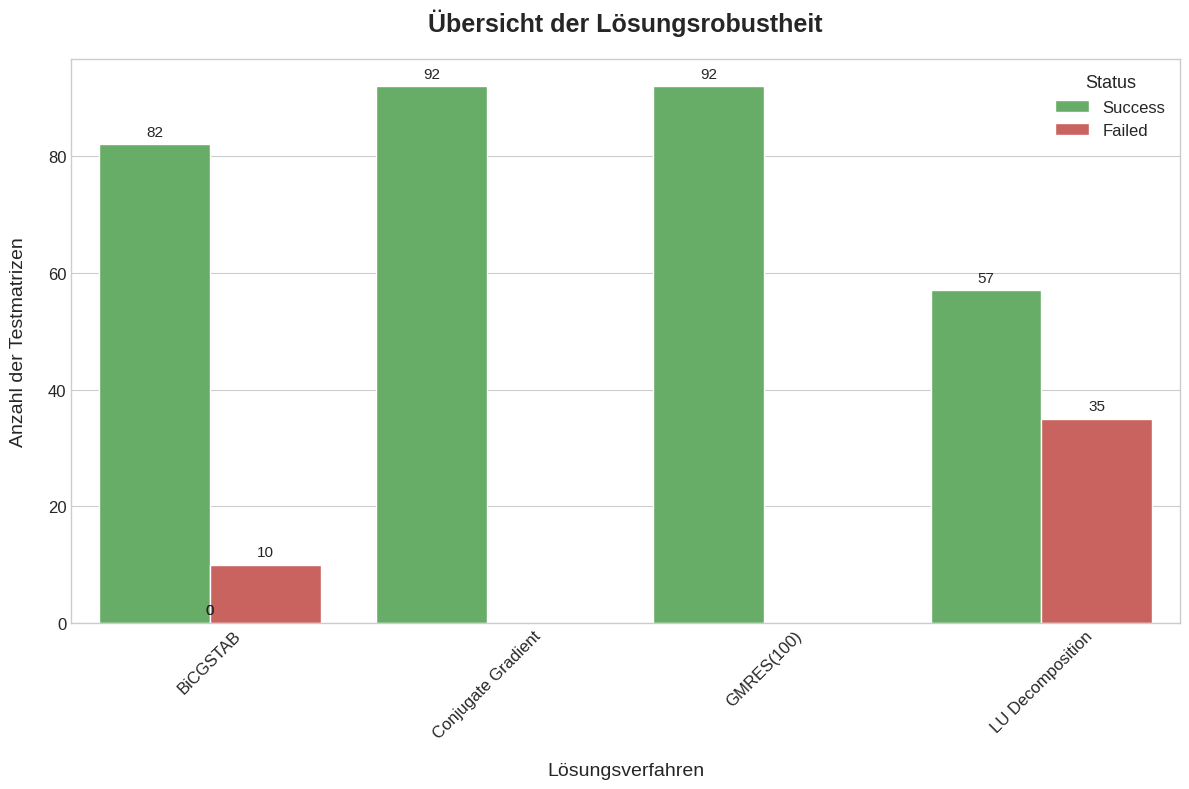

In [61]:


plot_solver_robustness_summary(summary_table, "plots/robustness_summary.png")
